# EN4554 – Assignment 2: Convolutional Neural Networks

**Name:** *Pirathishanth*  
**Index number:** *220480P*  
**GitHub  :** https://github.com/pirathi2002/EN4554-Assignment-2-Convolutional-Neural-Networks

---

### Contents
| Part | Topic | Rough run time on a Colab T4 |
|---|---|---|
| Setup | Data, utilities | 1 min |
| Task 1 | Backpropagation from scratch (Linear / ReLU / softmax-CE), gradient checks, MLP training, vanishing gradients | ~5 min |
| Task 2 | Own SGD-momentum and Adam, behaviour on an ill-conditioned quadratic, optimiser / learning-rate sweep on a CNN | ~15 min |
| Task 3 | Regularisation study on 5k images; plain vs residual networks of depth 8 / 20 / 56 | ~60–90 min |
| Task 4 (optional) | Best CNN with ≤ 500k parameters and ≤ 20 epochs, ablation, one-shot test evaluation | ~30 min |

### Use of AI tools (required acknowledgement)
I used Claude (Anthropic) to help generate the initial code structure and the interpretation drafts of this notebook. I ran all the experiments myself on a Colab T4, checked the interpretations against my own results, and I understand the code.

In [22]:
import os, time, math, random, json, copy
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt

QUICK = False          # True -> tiny subsets + 1-2 epochs: a smoke test of the whole notebook
QUICK_N = (3000, 600)  # (#train, #val) used in QUICK mode
SEED = 42

def E(full, quick=1):
    """Number of epochs: `full` normally, `quick` in QUICK mode."""
    return quick if QUICK else full

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

set_seed()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
print('torch', torch.__version__, '| device:', device, '| QUICK =', QUICK)

torch 2.11.0+cu130 | device: cuda | QUICK = False


## 0. Data: CIFAR-10, 45k / 5k split, per-channel normalisation

* The 50,000 official training images are split (fixed seed) into **45,000 train / 5,000 validation**.
* Each colour channel is normalised with the **mean / std of the 45k training images only** (no leakage from validation or test).
* The official 10,000-image **test set is not loaded here**; it is touched exactly once, at the very end of Task 4.
* The whole dataset is kept as tensors on the GPU, so training loops are fast and augmentation is done on the GPU as well.

train (45000, 3, 32, 32) | val (5000, 3, 32, 32)
channel mean [0.4917 0.4823 0.4467] | std [0.2471 0.2435 0.2616]
train class counts [4512, 4488, 4468, 4529, 4529, 4486, 4493, 4500, 4496, 4499]
val   class counts [488, 512, 532, 471, 471, 514, 507, 500, 504, 501]


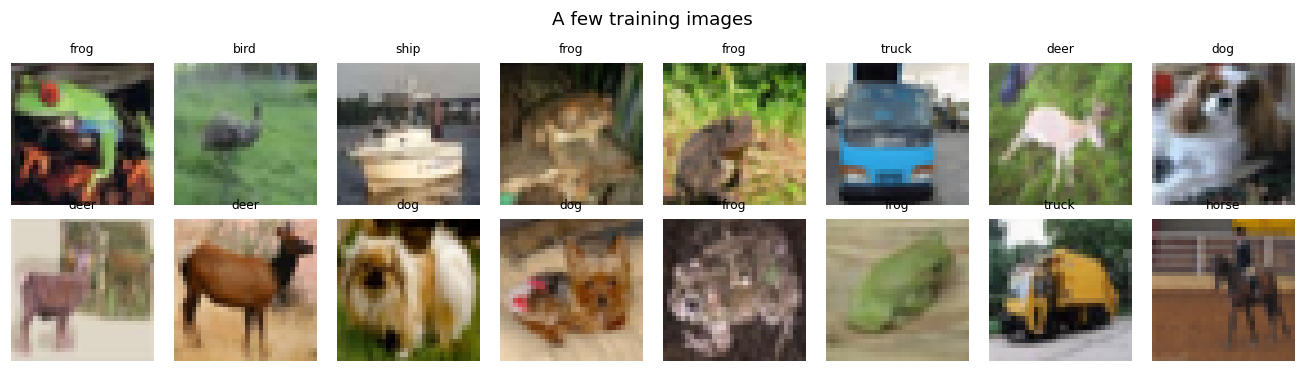

In [23]:
tv_train = torchvision.datasets.CIFAR10(root='./data', train=True, download=True)
CLASSES = tv_train.classes
X_u8 = torch.from_numpy(tv_train.data).permute(0, 3, 1, 2).contiguous()      # (50000,3,32,32) uint8
y_all = torch.tensor(tv_train.targets)

g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(X_u8), generator=g)
tr_idx, va_idx = perm[:45000], perm[45000:]
if QUICK:
    tr_idx, va_idx = tr_idx[:QUICK_N[0]], va_idx[:QUICK_N[1]]

Xtr_raw = X_u8[tr_idx].float().div(255)
mean = Xtr_raw.mean((0, 2, 3), keepdim=True)          # per-channel statistics of the TRAINING split only
std  = Xtr_raw.std((0, 2, 3), keepdim=True)
Xtr = ((Xtr_raw - mean) / std).to(device); ytr = y_all[tr_idx].to(device)
Xva = ((X_u8[va_idx].float().div(255) - mean) / std).to(device); yva = y_all[va_idx].to(device)
del Xtr_raw
mean_d, std_d = mean.to(device), std.to(device)
def denorm(x): return (x * std_d + mean_d).clamp(0, 1)

print('train', tuple(Xtr.shape), '| val', tuple(Xva.shape))
print('channel mean', mean.flatten().numpy().round(4), '| std', std.flatten().numpy().round(4))
print('train class counts', torch.bincount(ytr.cpu(), minlength=10).tolist())
print('val   class counts', torch.bincount(yva.cpu(), minlength=10).tolist())

fig, ax = plt.subplots(2, 8, figsize=(12, 3.4))
for i, a in enumerate(ax.flat):
    a.imshow(denorm(Xtr[i:i+1])[0].permute(1, 2, 0).cpu()); a.set_title(CLASSES[ytr[i]], fontsize=8); a.axis('off')
plt.suptitle('A few training images'); plt.tight_layout(); plt.show()

## Shared utilities
`evaluate` (loss / accuracy in eval mode) and `train_model` (a generic training loop that supports GPU augmentation, mixup, label smoothing, a per-step LR scheduler, and records per-epoch curves). Everything later reuses these.

In [24]:
def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

@torch.no_grad()
def evaluate(model, X, y, bs=1000):
    """Mean cross-entropy and accuracy of `model` (eval mode) on (X, y)."""
    was_training = model.training; model.eval()
    tot, ok = 0.0, 0
    for i in range(0, len(X), bs):
        out = model(X[i:i+bs])
        tot += F.cross_entropy(out, y[i:i+bs], reduction='sum').item()
        ok += (out.argmax(1) == y[i:i+bs]).sum().item()
    model.train(was_training)
    return tot / len(X), ok / len(X)

def warmup_cosine(opt, total_steps, warmup_steps=0):
    """Linear warm-up followed by cosine decay to 0; call .step() once per iteration."""
    def f(s):
        if s < warmup_steps: return (s + 1) / warmup_steps
        pr = (s - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1 + math.cos(math.pi * pr))
    return torch.optim.lr_scheduler.LambdaLR(opt, f)

def train_model(model, opt, epochs, Xt, yt, Xv, yv, bs=128, augment=None, mixup_alpha=0.0,
                scheduler=None, label_smoothing=0.0, eval_train=False, tag='', log_every=None):
    """Generic training loop. Returns a dict of per-epoch curves.
    train_loss : running mean of the (possibly augmented / mixed) minibatch loss during the epoch
    train_acc  : accuracy on the CLEAN training set in eval mode if eval_train else running accuracy
    val_*      : clean validation loss / accuracy in eval mode
    """
    model.to(device)
    hist = {k: [] for k in ['train_loss', 'train_acc', 'val_loss', 'val_acc', 'time']}
    hist['diverged'] = False
    n = len(Xt); nb = n // bs                       # drop the last incomplete batch (a new shuffle each epoch)
    log_every = log_every or max(1, epochs // 5)
    t0 = time.time()
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(n, device=Xt.device)
        run_loss = torch.zeros((), device=Xt.device); run_ok = torch.zeros((), device=Xt.device)
        for k in range(nb):
            b = perm[k*bs:(k+1)*bs]
            xb, yb = Xt[b], yt[b]
            if augment is not None: xb = augment(xb)
            if mixup_alpha > 0:                     # mixup: convex combination of two minibatches / label sets
                lam = float(np.random.beta(mixup_alpha, mixup_alpha))
                p = torch.randperm(len(xb), device=xb.device)
                out = model(lam * xb + (1 - lam) * xb[p])
                loss = lam * F.cross_entropy(out, yb, label_smoothing=label_smoothing) \
                     + (1 - lam) * F.cross_entropy(out, yb[p], label_smoothing=label_smoothing)
            else:
                out = model(xb)
                loss = F.cross_entropy(out, yb, label_smoothing=label_smoothing)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            if scheduler is not None: scheduler.step()
            run_loss += loss.detach() * len(b); run_ok += (out.argmax(1) == yb).sum()
        tl = run_loss.item() / (nb * bs)
        ta = evaluate(model, Xt, yt)[1] if eval_train else run_ok.item() / (nb * bs)
        vl, va = evaluate(model, Xv, yv)
        for k_, v_ in zip(['train_loss', 'train_acc', 'val_loss', 'val_acc', 'time'], [tl, ta, vl, va, time.time() - t0]):
            hist[k_].append(v_)
        if (ep + 1) % log_every == 0 or ep == 0 or ep == epochs - 1:
            print(f'[{tag}] ep {ep+1:3d}/{epochs} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f} | {time.time()-t0:5.0f}s')
        if not math.isfinite(tl):
            hist['diverged'] = True; print(f'[{tag}] diverged (loss = {tl}) - stopping early'); break
    return hist

# Task 2 – Optimisers

## 2(a) SGD with momentum and Adam as `torch.optim.Optimizer` subclasses

**SGD + momentum** (PyTorch convention): $g_t=\nabla L(\theta_{t-1})+\lambda\theta_{t-1}$, $\;v_t=\mu v_{t-1}+g_t$ (with $v_1=g_1$), $\;\theta_t=\theta_{t-1}-\eta v_t$.

**Adam** with bias correction: $m_t=\beta_1m_{t-1}+(1-\beta_1)g_t,\; v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2,\; \hat m_t=m_t/(1-\beta_1^t),\; \hat v_t=v_t/(1-\beta_2^t),\; \theta_t=\theta_{t-1}-\eta\,\hat m_t/(\sqrt{\hat v_t}+\varepsilon)$.

Both support (coupled, L2-style) weight decay $\lambda$ so that they can be compared with the built-in optimisers.

In [29]:
class MySGD(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-2, momentum=0.0, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, momentum=momentum, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad(): loss = closure()
        for grp in self.param_groups:
            for p in grp['params']:
                if p.grad is None: continue
                d = p.grad
                if grp['weight_decay'] != 0: d = d + grp['weight_decay'] * p
                if grp['momentum'] != 0:
                    st = self.state[p]
                    if 'buf' not in st: st['buf'] = d.clone()                    # v_1 = g_1
                    else: st['buf'].mul_(grp['momentum']).add_(d)                # v_t = mu v_{t-1} + g_t
                    d = st['buf']
                p.add_(d, alpha=-grp['lr'])
        return loss

class MyAdam(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad(): loss = closure()
        for grp in self.param_groups:
            b1, b2 = grp['betas']
            for p in grp['params']:
                if p.grad is None: continue
                g = p.grad
                if grp['weight_decay'] != 0: g = g + grp['weight_decay'] * p
                st = self.state[p]
                if not st:
                    st['t'] = 0; st['m'] = torch.zeros_like(p); st['v'] = torch.zeros_like(p)
                st['t'] += 1; t = st['t']
                st['m'].mul_(b1).add_(g, alpha=1 - b1)                           # first moment
                st['v'].mul_(b2).addcmul_(g, g, value=1 - b2)                    # second moment
                m_hat = st['m'] / (1 - b1 ** t)                                  # bias correction
                v_hat = st['v'] / (1 - b2 ** t)
                p.addcdiv_(m_hat, v_hat.sqrt().add_(grp['eps']), value=-grp['lr'])
        return loss
print('optimisers defined')

optimisers defined


**Verification against the built-ins.** The same small network (float64, identical initial weights, identical data) is trained for 100 full-batch steps with our optimiser and with the PyTorch one; we compare all parameters with `torch.allclose`.

In [30]:
def compare_optimizers(MyOpt, TorchOpt, kwargs, steps=100):
    def make():
        torch.manual_seed(0)
        return nn.Sequential(nn.Linear(20, 32), nn.Tanh(), nn.Linear(32, 5)).double()
    m1, m2 = make(), make()
    torch.manual_seed(1)
    x = torch.randn(64, 20, dtype=torch.float64); y = torch.randint(0, 5, (64,))
    o1, o2 = MyOpt(m1.parameters(), **kwargs), TorchOpt(m2.parameters(), **kwargs)
    for _ in range(steps):
        for m, o in ((m1, o1), (m2, o2)):
            o.zero_grad(); F.cross_entropy(m(x), y).backward(); o.step()
    diff = max((a - b).abs().max().item() for a, b in zip(m1.parameters(), m2.parameters()))
    ok = all(torch.allclose(a, b, rtol=1e-9, atol=1e-10) for a, b in zip(m1.parameters(), m2.parameters()))
    return diff, ok

tests = [('SGD',                    MySGD,  torch.optim.SGD,  dict(lr=0.1)),
         ('SGD + momentum 0.9',     MySGD,  torch.optim.SGD,  dict(lr=0.05, momentum=0.9)),
         ('SGD + mom. + wd 1e-3',   MySGD,  torch.optim.SGD,  dict(lr=0.05, momentum=0.9, weight_decay=1e-3)),
         ('Adam',                   MyAdam, torch.optim.Adam, dict(lr=1e-2)),
         ('Adam + wd 1e-3',         MyAdam, torch.optim.Adam, dict(lr=1e-2, weight_decay=1e-3)),
         ('Adam betas=(0.8,0.9)',   MyAdam, torch.optim.Adam, dict(lr=5e-3, betas=(0.8, 0.9)))]
print(f"{'configuration':26s}{'max |param diff| after 100 steps':>34s}{'allclose':>10s}")
for name, A, B, kw in tests:
    d, ok = compare_optimizers(A, B, kw)
    print(f'{name:26s}{d:34.2e}{str(ok):>10s}')

configuration               max |param diff| after 100 steps  allclose
SGD                                                 0.00e+00      True
SGD + momentum 0.9                                  0.00e+00      True
SGD + mom. + wd 1e-3                                5.55e-16      True
Adam                                                2.55e-14      True
Adam + wd 1e-3                                      1.25e-15      True
Adam betas=(0.8,0.9)                                3.73e-15      True


**Interpretation (2a).** For all six configurations (SGD, SGD with momentum, with and without weight decay, Adam with different betas) the maximum parameter difference after 100 steps is between 0 and 2.6e-14 and `torch.allclose` returns `True`. Our `MySGD` and `MyAdam` therefore perform the same updates as `torch.optim.SGD` and `torch.optim.Adam`. The tiny residual for Adam comes only from a different order of floating-point operations (PyTorch folds the bias correction into the step size). SGD matches exactly (difference 0) because it uses the identical sequence of operations.

## 2(b) Trajectories on an ill-conditioned quadratic

$f(x,y)=\tfrac12(x^2+50y^2)$ has Hessian $\mathrm{diag}(1,50)$ → condition number 50. Plain gradient descent is stable only for $\eta<2/\lambda_{\max}=0.04$ and then its speed along the flat $x$-direction is limited by $\eta\lambda_{\min}$. We start at $(x,y)=(8,1)$ and run each optimiser for 60 steps using **our own** optimisers on a 2-D parameter.

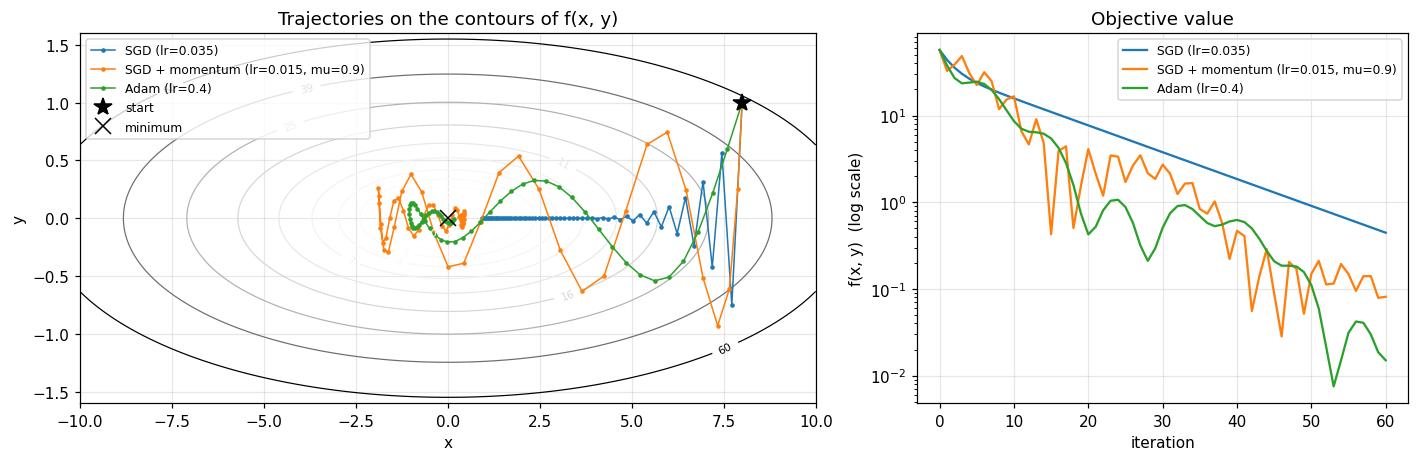

SGD (lr=0.035)                       final (x,y) = (+0.9435, +0.0000),  f = 4.451e-01
SGD + momentum (lr=0.015, mu=0.9)    final (x,y) = (+0.3574, +0.0263),  f = 8.121e-02
Adam (lr=0.4)                        final (x,y) = (+0.1717, -0.0034),  f = 1.503e-02


In [31]:
def f_quad(p): return 0.5 * (p[0] ** 2 + 50 * p[1] ** 2)

def run_traj(make_opt, start=(8.0, 1.0), steps=60):
    p = torch.tensor(start, requires_grad=True)
    opt = make_opt([p]); path = [p.detach().clone()]
    for _ in range(steps):
        opt.zero_grad(); f_quad(p).backward(); opt.step(); path.append(p.detach().clone())
    return torch.stack(path).numpy()

runs = {
    'SGD (lr=0.035)':                    run_traj(lambda ps: MySGD(ps, lr=0.035)),
    'SGD + momentum (lr=0.015, mu=0.9)': run_traj(lambda ps: MySGD(ps, lr=0.015, momentum=0.9)),
    'Adam (lr=0.4)':                     run_traj(lambda ps: MyAdam(ps, lr=0.4)),
}
cols = ['C0', 'C1', 'C2']
xs, ys = np.linspace(-10, 10, 400), np.linspace(-1.6, 1.6, 400)
Xg, Yg = np.meshgrid(xs, ys); Zg = 0.5 * (Xg ** 2 + 50 * Yg ** 2)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={'width_ratios': [1.5, 1]})
cs = ax[0].contour(Xg, Yg, Zg, levels=np.geomspace(0.5, 60, 12), cmap='Greys', linewidths=0.8)
ax[0].clabel(cs, inline=True, fontsize=7, fmt='%.0f')
for (name, path), c in zip(runs.items(), cols):
    ax[0].plot(path[:, 0], path[:, 1], '.-', color=c, ms=4, lw=1, label=name)
ax[0].plot(*runs['SGD (lr=0.035)'][0], 'k*', ms=12, label='start'); ax[0].plot(0, 0, 'kx', ms=10, label='minimum')
ax[0].set_xlabel('x'); ax[0].set_ylabel('y'); ax[0].set_title('Trajectories on the contours of f(x, y)'); ax[0].legend(fontsize=8, loc='upper left')
for (name, path), c in zip(runs.items(), cols):
    ax[1].semilogy(0.5 * (path[:, 0] ** 2 + 50 * path[:, 1] ** 2) + 1e-12, color=c, label=name)
ax[1].set_xlabel('iteration'); ax[1].set_ylabel('f(x, y)  (log scale)'); ax[1].set_title('Objective value'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
for name, path in runs.items():
    print(f'{name:36s} final (x,y) = ({path[-1,0]:+.4f}, {path[-1,1]:+.4f}),  f = {0.5*(path[-1,0]**2+50*path[-1,1]**2):.3e}')

**Interpretation (2b).** After 60 steps the objective values are 0.445 for SGD, 0.081 for SGD with momentum and 0.015 for Adam. **SGD** must use lr < 2/λ_max = 0.04, so it is limited by the steep y-direction: y zig-zags with factor 1 − 50η = −0.75 and dies out, while x only shrinks by 1 − η = 0.965 per step (x = 0.94 after 60 steps), giving a smooth but slow monotone path governed by the condition number 50. **Momentum** accumulates the consistent x-gradient (effective step η/(1−μ)), so it moves along x faster, but it overshoots the minimum and oscillates in both directions (it crosses to negative x). **Adam** divides each coordinate by √v̂, so x and y progress at similar speeds regardless of curvature and it reaches the lowest objective value, but with a constant learning rate of 0.4 it also overshoots and oscillates around the minimum with slowly decreasing amplitude, so its objective is not monotone.

## 2(c) Optimiser × learning-rate study on a small CNN

A small CNN **without batch norm** (3 × [conv3×3 – ReLU – maxpool], widths 32/64/128, Kaiming init, ≈0.11M parameters) is trained for 10 epochs (batch 128) on the 45k training images with each of **plain SGD, SGD with momentum 0.9, Adam** (our implementations from 2(a)) at **three learning rates each** (same seed / same initial weights for every run). Not using batch norm makes the sensitivity to the learning rate clearly visible.

In [32]:
class SmallCNN(nn.Module):
    """stages of [conv3x3 (-BN) -ReLU] x convs, then maxpool (-dropout); final linear layer on the 4x4 feature map."""
    def __init__(self, widths=(32, 64, 128), convs=1, bn=False, p_drop=0.0):
        super().__init__()
        L, cin = [], 3
        for w in widths:
            for _ in range(convs):
                L.append(nn.Conv2d(cin, w, 3, padding=1, bias=not bn))
                if bn: L.append(nn.BatchNorm2d(w))
                L.append(nn.ReLU(inplace=True)); cin = w
            L.append(nn.MaxPool2d(2))
            if p_drop > 0: L.append(nn.Dropout(p_drop))
        L += [nn.Flatten(), nn.Linear(cin * 4 * 4, 10)]
        self.net = nn.Sequential(*L)
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
                if m.bias is not None: nn.init.zeros_(m.bias)
    def forward(self, x): return self.net(x)

print('SmallCNN (no BN) parameters:', count_params(SmallCNN()))

def make_opt(name, params, lr, wd=0.0):
    if name == 'SGD':          return MySGD(params, lr=lr, momentum=0.0, weight_decay=wd)
    if name == 'SGD+momentum': return MySGD(params, lr=lr, momentum=0.9, weight_decay=wd)
    if name == 'Adam':         return MyAdam(params, lr=lr, weight_decay=wd)

SWEEP = {'SGD': [1e-3, 1e-2, 1e-1], 'SGD+momentum': [1e-3, 1e-2, 1e-1], 'Adam': [1e-4, 1e-3, 1e-2]}
EPOCHS_2C = E(10, 2)
sweep = {}
for opt_name, lrs in SWEEP.items():
    for lr in lrs:
        set_seed()                                     # identical initial weights and data order for every run
        model = SmallCNN().to(device)
        sweep[(opt_name, lr)] = train_model(model, make_opt(opt_name, model.parameters(), lr), EPOCHS_2C,
                                            Xtr, ytr, Xva, yva, bs=128, tag=f'{opt_name} lr={lr:g}', log_every=EPOCHS_2C)

SmallCNN (no BN) parameters: 113738
[SGD lr=0.001] ep   1/10 | train loss 1.964 acc 0.294 | val loss 1.798 acc 0.363 |     2s
[SGD lr=0.001] ep  10/10 | train loss 1.369 acc 0.522 | val loss 1.392 acc 0.512 |    19s
[SGD lr=0.01] ep   1/10 | train loss 1.724 acc 0.401 | val loss 1.488 acc 0.470 |     2s
[SGD lr=0.01] ep  10/10 | train loss 0.889 acc 0.693 | val loss 0.983 acc 0.651 |    18s
[SGD lr=0.1] ep   1/10 | train loss 1.804 acc 0.396 | val loss 1.337 acc 0.522 |     2s
[SGD lr=0.1] ep  10/10 | train loss 0.668 acc 0.768 | val loss 0.867 acc 0.705 |    18s
[SGD+momentum lr=0.001] ep   1/10 | train loss 1.657 acc 0.410 | val loss 1.463 acc 0.481 |     2s
[SGD+momentum lr=0.001] ep  10/10 | train loss 0.853 acc 0.707 | val loss 0.975 acc 0.658 |    18s
[SGD+momentum lr=0.01] ep   1/10 | train loss 1.593 acc 0.442 | val loss 1.245 acc 0.561 |     2s
[SGD+momentum lr=0.01] ep  10/10 | train loss 0.573 acc 0.800 | val loss 0.828 acc 0.732 |    18s
[SGD+momentum lr=0.1] ep   1/10 | tr

optimiser            lr  final val acc  best val acc  final train loss
SGD               1e-03         0.5122        0.5122            1.3690
SGD               1e-02         0.6506        0.6506            0.8895
SGD               1e-01         0.7048        0.7090            0.6675
SGD+momentum      1e-03         0.6584        0.6584            0.8535
SGD+momentum      1e-02         0.7320        0.7320            0.5730
SGD+momentum      1e-01         0.1008        0.1064            2.3043
Adam              1e-04         0.6350        0.6350            0.9537
Adam              1e-03         0.7230        0.7250            0.3055
Adam              1e-02         0.5586        0.5586            1.2242
best learning rate per optimiser: {'SGD': 0.1, 'SGD+momentum': 0.01, 'Adam': 0.001}


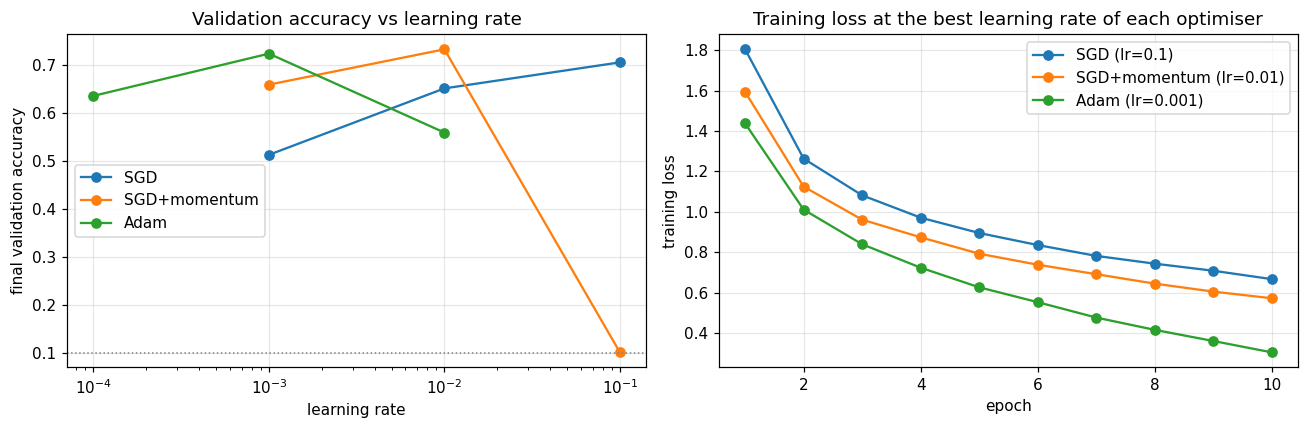

In [33]:
def final_val(h): return 0.10 if h['diverged'] else h['val_acc'][-1]       # chance level (10%) for diverged runs

print(f"{'optimiser':14s}{'lr':>9s}{'final val acc':>15s}{'best val acc':>14s}{'final train loss':>18s}")
best = {}
for (o, lr), h in sweep.items():
    fv = final_val(h)
    print(f"{o:14s}{lr:9.0e}{fv:15.4f}{(max(h['val_acc']) if not h['diverged'] else 0.10):14.4f}{(h['train_loss'][-1] if not h['diverged'] else float('nan')):18.4f}")
    if o not in best or fv > final_val(sweep[(o, best[o])]): best[o] = lr
print('best learning rate per optimiser:', best)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for (o, lrs), c in zip(SWEEP.items(), ['C0', 'C1', 'C2']):
    ax[0].plot(lrs, [final_val(sweep[(o, lr)]) for lr in lrs], 'o-', color=c, label=o)
ax[0].set_xscale('log'); ax[0].set_xlabel('learning rate'); ax[0].set_ylabel('final validation accuracy')
ax[0].set_title('Validation accuracy vs learning rate'); ax[0].axhline(0.1, color='gray', ls=':', lw=1); ax[0].legend()
for (o, lr_b), c in zip(best.items(), ['C0', 'C1', 'C2']):
    h = sweep[(o, lr_b)]
    ax[1].plot(range(1, len(h['train_loss']) + 1), h['train_loss'], 'o-', color=c, label=f'{o} (lr={lr_b:g})')
ax[1].set_xlabel('epoch'); ax[1].set_ylabel('training loss'); ax[1].set_title('Training loss at the best learning rate of each optimiser'); ax[1].legend()
plt.tight_layout(); plt.show()

**Interpretation (2c).** The best validation accuracies are 73.2% for SGD with momentum (lr 0.01), 72.3% for Adam (lr 1e-3) and 70.5% for plain SGD (lr 0.1). The three are close, but the learning-rate sensitivity differs strongly. **SGD with momentum** has the sharpest cliff: lr 1e-3 gives 65.8%, lr 1e-2 gives 73.2% and lr 0.1 collapses to chance (10.1%, loss stuck at 2.304 = ln 10), because momentum 0.9 multiplies the effective step by about 10 so lr 0.1 behaves like lr 1.0. **Adam** is peaked: both neighbours are worse (63.5% at 1e-4, too slow; 55.9% at 1e-2, too noisy without batch norm), but it never collapses. **Plain SGD** improves monotonically across the grid (51.2% → 65.1% → 70.5%); its best value is at the edge of the grid, so a larger lr might do even better and it is probably under-tuned. At the best learning rates Adam reduces the training loss fastest (0.31 vs 0.57 for momentum and 0.67 for SGD), yet its validation accuracy is slightly lower and its validation loss is higher (0.97 vs 0.83), i.e. Adam fits the training data faster but generalises a little worse here. Caveat: one seed and only 10 epochs, so differences of about 1% are within noise.